# Homework 3: Noise and Linear Light
## Name: Jon Knapp
### Date: November 12, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

I used Claude (Anthropic) to review my notebook against the assignment, write and debug the analysis code, check my flat-field and dark-frame captures before I reshot them, and draft the written answers, which I then reviewed and edited. I verified its work by running the photon-transfer code on the lecture 5 simulated sensor with known gain and read noise (item 4), cross-checking the fitted read noise against an independent dark-frame measurement, testing the sRGB functions with a round-trip check, and confirming that every number in the written answers matches the notebook's printed output.

## Part 1: Captures
### Problem 1: Capture at least ten pairs of flat fields spanning the range from nearly black to nearly saturated, two frames at each level with nothing moved or changed between them.
 _Deliverables: A contact sheet showing one frame from each pair, and a list giving the exposure time and ISO of every capture._

In [1]:
# If rawpy isn't installed:  %pip install rawpy
from fractions import Fraction
from pathlib import Path
import tifffile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
from matplotlib.patches import Rectangle

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"
PATCH = 128   # side of the central measurement patch, in green-plane pixels

# Sheets of printer paper between the window and the lens for each flat field.
# Several light levels share an exposure time (1/30 s at 10, 4, 3 and 2 sheets),
# so a pair is identified by (sheets, exposure time), not by exposure time alone.
SHEETS = {
    **{f"IMG_{n:04d}": 10 for n in range(843, 857)},   # 10 sheets, 1/30 s to 1 s
    "IMG_0872": 4, "IMG_0873": 4,                       # 4 sheets, 1/30 s
    "IMG_0874": 3, "IMG_0875": 3,                       # 3 sheets, 1/30 s
    "IMG_0876": 2, "IMG_0877": 2,                       # 2 sheets, 1/30 s
}


In [2]:
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None

def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {Path(path).name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so the two frames of a pair group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {Path(path).name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    return f"{float(f):.3g} s" if f >= 1 else f"1/{1 / f:.4g} s"


def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files

In [3]:
def green_plane(path):
    """Return (green plane in DN, black level of that plane, white level).
    Takes the first green site of the 2x2 Bayer tile, so it is one green
    channel, not a mix of G1 and G2."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)   # copy before the file closes
        pattern = r.raw_pattern
        desc = r.color_desc.decode()
        gi, gj = next((i, j) for i in range(2) for j in range(2)
                      if desc[pattern[i, j]] == "G")
        black = float(r.black_level_per_channel[pattern[gi, gj]])
        white = float(r.white_level)
    return raw[gi::2, gj::2], black, white


def center_patch(plane, n=PATCH):
    h, w = plane.shape
    top, left = (h - n) // 2, (w - n) // 2
    return plane[top:top + n, left:left + n]

In [4]:
def capture_table(folder):
    rows = []
    for f in dng_files(folder):
        if f.stem not in SHEETS:
            raise KeyError(f"{f.name} has no entry in SHEETS; add its sheet count in the setup cell.")
        et = exposure_of(f)
        g, black, white = green_plane(f)
        m = center_patch(g).mean()
        rows.append({
            "file": f.name,
            "sheets": SHEETS[f.stem],
            "exposure": fmt_exposure(et),
            "exposure_s": float(et),
            "ISO": iso_of(f),
            "black_DN": black,
            "white_DN": white,
            "center_mean_DN": m,
            "pct_saturation": 100 * (m - black) / (white - black),
        })
    df = pd.DataFrame(rows)
    # One pair = one (sheets, exposure time) setting. Number the pairs from darkest to brightest.
    level = df.groupby(["sheets", "exposure_s"]).center_mean_DN.transform("mean")
    df = (df.assign(_level=level).sort_values(["_level", "file"])
            .drop(columns="_level").reset_index(drop=True))
    df.insert(0, "pair", df.groupby(["sheets", "exposure_s"], sort=False).ngroup() + 1)
    return df


white_df = capture_table(WHITE_DIR)
white_df.round({"exposure_s": 5, "center_mean_DN": 1, "pct_saturation": 1})

,pair,file,sheets,exposure,exposure_s,ISO,black_DN,white_DN,center_mean_DN,pct_saturation
0,1,IMG_0843.DNG,10,1/30 s,0.03333,50,528.0,4095.0,561.2,0.9
1,1,IMG_0844.DNG,10,1/30 s,0.03333,50,528.0,4095.0,561.3,0.9
2,2,IMG_0845.DNG,10,1/15 s,0.06667,50,528.0,4095.0,594.9,1.9
3,2,IMG_0846.DNG,10,1/15 s,0.06667,50,528.0,4095.0,595.0,1.9
4,3,IMG_0847.DNG,10,1/8 s,0.12500,50,528.0,4095.0,654.2,3.5
5,3,IMG_0848.DNG,10,1/8 s,0.12500,50,528.0,4095.0,654.1,3.5
6,4,IMG_0849.DNG,10,1/4 s,0.25000,50,528.0,4095.0,781.6,7.1
7,4,IMG_0850.DNG,10,1/4 s,0.25000,50,528.0,4095.0,781.6,7.1
8,5,IMG_0851.DNG,10,1/3 s,0.33333,50,528.0,4095.0,867.6,9.5
9,5,IMG_0852.DNG,10,1/3 s,0.33333,50,528.0,4095.0,867.7,9.5


In [5]:
counts = white_df.groupby("pair").size()
bad_pairs = counts[counts != 2]
short = white_df[white_df.exposure_s < 1 / 50]

print(f"{len(white_df)} flat-field frames, {white_df.pair.nunique()} light levels (sheets x exposure)")
print(f"ISO value(s): {sorted(int(i) for i in white_df.ISO.unique())}")
print(f"Central-patch level spans {white_df.pct_saturation.min():.1f}% "
      f"to {white_df.pct_saturation.max():.1f}% of saturation")
if white_df.pair.nunique() < 10:
    print("! Fewer than 10 levels; the assignment asks for at least ten pairs.")
if len(bad_pairs):
    print("! Levels without exactly 2 frames:", dict(bad_pairs))
if len(short):
    print("! Exposures shorter than 1/50 s (screen flicker risk):",
          ", ".join(short.file))

20 flat-field frames, 10 light levels (sheets x exposure)
ISO value(s): [50]
Central-patch level spans 0.9% to 96.0% of saturation


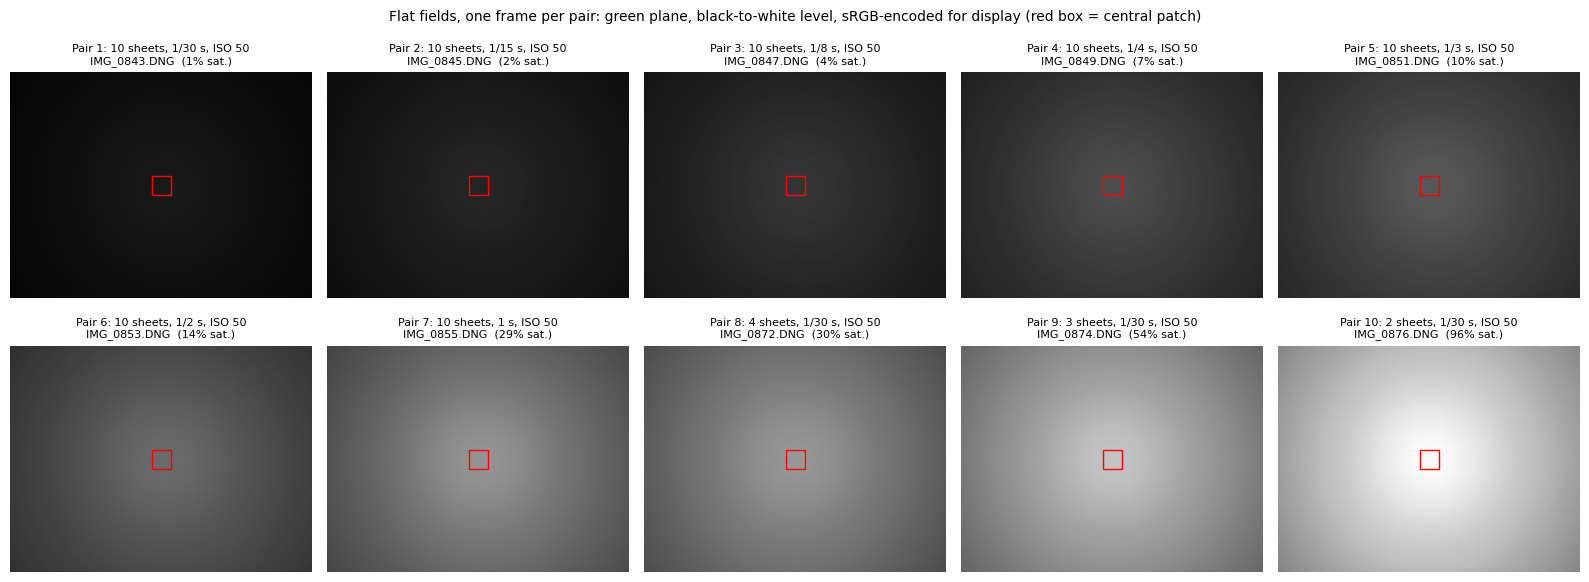

In [6]:
def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


def thumbnail(plane, black, white, factor=8):
    """Normalize to [0, 1] of the raw range, block-average in linear light, then encode."""
    x = (plane - black) / (white - black)
    h, w = (s // factor * factor for s in x.shape)
    x = x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))
    return srgb_encode(x)


FACTOR = 8
reps = white_df.groupby("pair").first().reset_index()
ncols = 5
nrows = int(np.ceil(len(reps) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.1 * nrows), squeeze=False)

for ax, row in zip(axes.flat, reps.itertuples()):
    g, black, white = green_plane(WHITE_DIR / row.file)
    t = thumbnail(g, black, white, FACTOR)
    ax.imshow(t, cmap="gray", vmin=0, vmax=1)
    # outline the central patch used in Part 2
    s = PATCH / FACTOR
    ax.add_patch(Rectangle(((t.shape[1] - s) / 2, (t.shape[0] - s) / 2), s, s,
                           fill=False, edgecolor="red", linewidth=1))
    ax.set_title(f"Pair {row.pair}: {row.sheets} sheets, {row.exposure}, ISO {row.ISO}\n"
                 f"{row.file}  ({row.pct_saturation:.0f}% sat.)", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(reps):]:
    ax.axis("off")

fig.suptitle("Flat fields, one frame per pair: green plane, black-to-white level, "
             "sRGB-encoded for display (red box = central patch)", fontsize=10)
fig.tight_layout()
fig.savefig("hw3_item1_contact_sheet.png", dpi=150, bbox_inches="tight")
plt.show()

Flat fields were taken through sheets of printer paper held against the lens, facing an overcast window, at ISO 50. The app’s exposure range (1/30 to 1 s) covers only about 5 stops, so the light level was also set by the number of sheets: 10 sheets for exposures from 1/30 to 1 s, then 4, 3 and 2 sheets at 1/30 s to reach the upper half of the range. Only the two frames within a pair need to match, so changing sheets between pairs does not affect the measurement. The darkening toward the edges of each frame is lens shading, which is why Part 2 measures only the central patch.

In [7]:
white_df[["pair", "file", "sheets", "exposure", "exposure_s", "ISO", "pct_saturation"]].style.format({"exposure_s": "{:.4f}", "pct_saturation": "{:.1f}"}).hide(axis="index")

pair,file,sheets,exposure,exposure_s,ISO,pct_saturation
1,IMG_0843.DNG,10,1/30 s,0.0333,50,0.9
1,IMG_0844.DNG,10,1/30 s,0.0333,50,0.9
2,IMG_0845.DNG,10,1/15 s,0.0667,50,1.9
2,IMG_0846.DNG,10,1/15 s,0.0667,50,1.9
3,IMG_0847.DNG,10,1/8 s,0.1250,50,3.5
3,IMG_0848.DNG,10,1/8 s,0.1250,50,3.5
4,IMG_0849.DNG,10,1/4 s,0.2500,50,7.1
4,IMG_0850.DNG,10,1/4 s,0.2500,50,7.1
5,IMG_0851.DNG,10,1/3 s,0.3333,50,9.5
5,IMG_0852.DNG,10,1/3 s,0.3333,50,9.5


### Problem 2: Confirm from the metadata that the entire series came from one camera at one ISO, using the lens_id helper from the Project 1 page together with the ISO field.
_Deliverable: The assertion passing, or an account of which captures differ and what you did about it._

In [8]:
"""
Homework 3 (Noise and Linear Light), Item 2:
Confirm from the metadata that every capture came from one camera at one ISO.

Run from the folder that contains "Homework 3 Image Captures":
    python hw3_item2_metadata_check.py

It prints a table of every DNG (lens, focal length, frame size, ISO, exposure),
groups the flat fields by sheets and exposure time so you can see the pairs, and asserts
that each series has exactly one camera and one ISO. The table doubles as the
"exposure time and ISO of every capture" list for item 1.
"""

from collections import defaultdict
from fractions import Fraction
from pathlib import Path

import tifffile

CAPTURE_ROOT = Path("Homework 3 Image Captures")
WHITE_DIR = CAPTURE_ROOT / "White Frames"
DARK_DIR = CAPTURE_ROOT / "Dark Frames"

# Sheet counts from the notebook's setup cell, if it has been run; dark frames have none.
SHEETS = globals().get("SHEETS", {})


# --- lens_id helper, as given on the Project 1 page --------------------------
def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


# --- ISO and exposure time ----------------------------------------------------
def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0.
    iPhone raw apps put ISO/exposure in the EXIF IFD; Android's DngCreator
    (Open Camera) writes them into IFD0 directly."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def iso_of(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings")
        if iso is None:
            iso = _lookup(p, "PhotographicSensitivity")
    if isinstance(iso, (tuple, list)):
        iso = iso[0]
    if iso is None:
        raise KeyError(f"No ISO field found in {path.name}")
    return int(iso)


def exposure_of(path):
    """Exposure time in seconds, as a Fraction so pairs group exactly."""
    with tifffile.TiffFile(path) as t:
        et = _lookup(t.pages[0], "ExposureTime")
    if et is None:
        raise KeyError(f"No ExposureTime field found in {path.name}")
    if isinstance(et, (tuple, list)):
        return Fraction(int(et[0]), int(et[1]))
    return Fraction(et).limit_denominator(1_000_000)


def fmt_exposure(f):
    if f >= 1:
        return f"{float(f):.3g} s"
    return f"1/{1 / f:.4g} s"


# --- per-series check ---------------------------------------------------------
def dng_files(folder):
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder.resolve()}")
    files = sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")
    if not files:
        raise FileNotFoundError(f"No .dng files in {folder.resolve()}")
    return files


def describe_series(name, files):
    rows = []
    for f in files:
        rows.append((f, lens_id(f), iso_of(f), exposure_of(f)))

    print(f"\n=== {name}: {len(files)} files ===")
    print(f"{'file':<28} {'ISO':>5} {'exposure':>12}  lens")
    for f, lid, iso, et in rows:
        print(f"{f.name:<28} {iso:>5} {fmt_exposure(et):>12}  {lid[0]}, "
              f"{lid[1]} mm, {lid[2]} mm equiv, {lid[3][0]}x{lid[3][1]}")

    lens_ids = {lid for _, lid, _, _ in rows}
    isos = {iso for _, _, iso, _ in rows}

    # If something differs, say which files, before the assert fires.
    for label, values, idx in (("camera", lens_ids, 1), ("ISO", isos, 2)):
        if len(values) > 1:
            print(f"\n  ! More than one {label} in {name}:")
            groups = defaultdict(list)
            for r in rows:
                groups[r[idx]].append(r[0].name)
            for v, names in groups.items():
                print(f"    {v}: {', '.join(names)}")

    return rows, lens_ids, isos


def print_pairs(rows, expected=2, check_flicker=True):
    """Group captures by (sheets of paper, exposure time); each level should hold
    `expected` frames (2 for a flat-field pair, 5 for dark frames)."""
    by_level = defaultdict(list)
    for f, _, _, et in rows:
        by_level[(SHEETS.get(f.stem), et)].append(f.name)
    print(f"\n  Levels ({len(by_level)} settings of sheets x exposure time):")
    for sheets, et in sorted(by_level, key=lambda k: (-(k[0] or 0), k[1])):
        names = by_level[(sheets, et)]
        label = f"{sheets} sheets, {fmt_exposure(et)}" if sheets else fmt_exposure(et)
        flag = "" if len(names) >= expected else f"   <-- {len(names)} frames, expected {expected}"
        print(f"    {label:>20}: {', '.join(names)}{flag}")
    short = sorted({et for _, et in by_level if et < Fraction(1, 50)})
    if check_flicker and short:
        print("  ! Exposures shorter than 1/50 s (screen flicker risk): "
              + ", ".join(fmt_exposure(e) for e in short))


if __name__ == "__main__":
    white_rows, white_lens, white_iso = describe_series("White Frames",
                                                        dng_files(WHITE_DIR))
    print_pairs(white_rows, expected=2)
    dark_rows, dark_lens, dark_iso = describe_series("Dark Frames",
                                                     dng_files(DARK_DIR))
    print_pairs(dark_rows, expected=5, check_flicker=False)

    all_lens = white_lens | dark_lens
    all_iso = white_iso | dark_iso
    print("\nCamera(s):", all_lens)
    print("ISO(s):   ", all_iso)

    assert len(white_lens) == 1, f"more than one camera in white frames: {white_lens}"
    assert len(white_iso) == 1, f"more than one ISO in white frames: {white_iso}"
    assert len(dark_lens) == 1, f"more than one camera in dark frames: {dark_lens}"
    assert len(dark_iso) == 1, f"more than one ISO in dark frames: {dark_iso}"
    assert all_lens == white_lens, f"dark and white frames from different cameras: {all_lens}"
    assert all_iso == white_iso, f"dark and white frames at different ISOs: {all_iso}"
    print("\nPASS: all captures from one camera at one ISO.")


=== White Frames: 20 files ===
file                           ISO     exposure  lens
IMG_0843.DNG                    50       1/30 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0844.DNG                    50       1/30 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0845.DNG                    50       1/15 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0846.DNG                    50       1/15 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0847.DNG                    50        1/8 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0848.DNG                    50        1/8 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0849.DNG                    50        1/4 s  iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765 mm, 24 mm equiv, 4032x3024
IMG_0850.DNG      

### Problem 3: Capture five dark frames with the lens covered at each of four exposure times, spanning the longest range your app allows, and compare their level against the black level recorded in the file.
_Deliverable: The black level per channel from the file, the mean of your shortest dark frames in digital numbers, and one sentence on whether the two agree._

In [9]:
def bayer_channels(path):
    """Black level from the file and measured statistics for each of the four Bayer sites."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)
        pattern = r.raw_pattern.copy()
        desc = r.color_desc.decode()
        blacks = [float(b) for b in r.black_level_per_channel]
    out, g_count = [], 0
    for i in range(2):
        for j in range(2):
            c = pattern[i, j]
            name = desc[c]
            if name == "G":                      # label the two green sites G1 and G2
                g_count += 1
                name = f"G{g_count}"
            site = raw[i::2, j::2]
            out.append({"channel": name,
                        "black_DN": blacks[c],
                        "mean_DN": site.mean(),
                        "std_DN": site.std()})
    return out

In [10]:
rows = []
for f in dng_files(DARK_DIR):
    et = exposure_of(f)
    for ch in bayer_channels(f):
        rows.append({"file": f.name, "exposure": fmt_exposure(et),
                     "exposure_s": float(et), "ISO": iso_of(f), **ch})
dark_ch = pd.DataFrame(rows)

per_level = (dark_ch.groupby("exposure_s")
             .agg(exposure=("exposure", "first"), frames=("file", "nunique")))
print(f"{dark_ch.file.nunique()} dark frames at {len(per_level)} exposure times, "
      f"spanning {per_level.exposure.iloc[0]} to {per_level.exposure.iloc[-1]}")
for _, r in per_level.iterrows():
    flag = "" if r.frames >= 5 else f"   <-- {r.frames} frames, need 5"
    print(f"  {r.exposure:>10}: {r.frames} frames{flag}")
if len(per_level) < 4:
    print("! Fewer than 4 exposure times.")

23 dark frames at 4 exposure times, spanning 1/30 s to 1 s
      1/30 s: 5 frames
       1/4 s: 6 frames
       1/2 s: 6 frames
         1 s: 6 frames


In [11]:
spread = dark_ch.groupby("channel").black_DN.agg(["min", "max"])
if (spread["min"] != spread["max"]).any():
    print("! The recorded black level differs between files:")
    print(spread)

black_per_channel = dark_ch.groupby("channel", sort=False).black_DN.first().to_frame()
black_per_channel

,black_DN
channel,
B,528.0
G1,528.0
G2,528.0
R,528.0


In [12]:
t_min = dark_ch.exposure_s.min()
shortest = dark_ch[dark_ch.exposure_s == t_min]
n_frames = shortest.file.nunique()
print(f"Shortest exposure: {fmt_exposure(Fraction(t_min).limit_denominator(1_000_000))}, "
      f"{n_frames} frames: {', '.join(shortest.file.unique())}")

summary = shortest.groupby("channel", sort=False).agg(
    black_DN=("black_DN", "first"),
    mean_DN=("mean_DN", "mean"),
    frame_to_frame_sd_DN=("mean_DN", "std"),   # spread of the per-frame means
    pixel_std_DN=("std_DN", "mean"),           # noise within one frame
)
summary["mean_minus_black_DN"] = summary.mean_DN - summary.black_DN
summary["std_error_DN"] = summary.frame_to_frame_sd_DN / np.sqrt(n_frames)

all_mean = shortest.mean_DN.mean()
all_black = shortest.black_DN.mean()
print(f"All channels: mean {all_mean:.2f} DN vs. black level {all_black:.2f} DN "
      f"(difference {all_mean - all_black:+.2f} DN)")

display(summary.round(3))

diff = all_mean - all_black
print(f"Shortest dark frames: {all_mean:.2f} DN vs. recorded black level {all_black:.0f} DN, "
      f"difference {diff:+.2f} DN ({100 * diff / (4095 - all_black):+.3f}% of the raw range)")

Shortest exposure: 1/30 s, 5 frames: IMG_0901.DNG, IMG_0902.DNG, IMG_0903.DNG, IMG_0904.DNG, IMG_0905.DNG
All channels: mean 527.42 DN vs. black level 528.00 DN (difference -0.58 DN)


,black_DN,mean_DN,frame_to_frame_sd_DN,pixel_std_DN,mean_minus_black_DN,std_error_DN
channel,,,,,,
B,528.0,527.340,0.002,1.709,-0.660,0.001
G1,528.0,527.483,0.041,1.712,-0.517,0.018
G2,528.0,527.483,0.041,1.715,-0.517,0.018
R,528.0,527.361,0.003,1.851,-0.639,0.001


Shortest dark frames: 527.42 DN vs. recorded black level 528 DN, difference -0.58 DN (-0.016% of the raw range)


The file records a black level of 528 DN in all four channels. The five 1/30 s dark frames average 527.42 DN (527.48 DN in both greens, 527.34–527.36 DN in red and blue), so the two agree to within 0.7 DN, about 0.02% of the 3567 DN range, with the measured level slightly below the recorded value in every channel.

## Part 2: The Photon Transfer Curve

### Problem 4: Before fitting any of your own data, run your photon transfer code on the simulated sensor in the lecture 5 demo notebook, which reports the true gain and read noise it used to generate the frames.
_Deliverable: Your recovered gain and read noise beside the true values, as percentage errors._

In [13]:
def pair_stats(a, b, black, n=PATCH):
    """Mean above black and single-frame variance from one flat-field pair.
    Mean: average of the two frame means, black subtracted.
    Variance: half the variance of the difference, so fixed pattern cancels."""
    a = center_patch(np.asarray(a, dtype=np.float64), n)
    b = center_patch(np.asarray(b, dtype=np.float64), n)
    mean = 0.5 * (a.mean() + b.mean()) - black
    var = np.var(a - b, ddof=1) / 2
    return mean, var, a.size


Q_VAR = 1 / 12   # DN^2 added to every variance by rounding to whole digital numbers


def fit_ptc(mean, var, full_scale, frac=0.70, weighted=True, quantization=True):
    """Fit Var = K * mean + K^2 sigma_r^2 to the points below `frac` of full scale.

    full_scale is white level minus black level, in DN. With weighted=True each
    point is weighted by 1/variance, since the scatter of a variance estimate is
    proportional to the variance itself; this keeps the bright points from
    dominating the intercept. Rounding to whole DN adds 1/12 DN^2 to every
    variance, which the model does not contain; with quantization=True that is
    removed from the intercept before the read noise is computed, so sigma_r is
    the analog read noise. Returns gain and read noise with 1-sigma
    uncertainties from the fit covariance."""
    mean = np.asarray(mean, dtype=np.float64)
    var = np.asarray(var, dtype=np.float64)
    used = (mean > 0) & (mean < frac * full_scale)
    if used.sum() < 4:
        raise ValueError(f"Only {used.sum()} points below {frac:.0%} of saturation; need at least 4.")

    w = 1 / var[used] if weighted else None
    (K, c), cov = np.polyfit(mean[used], var[used], 1, w=w, cov=True)
    sig_K, sig_c = np.sqrt(np.diag(cov))
    c_read = c - Q_VAR if quantization else c    # K^2 sigma_r^2 in DN^2, rounding removed

    if c_read > 0:
        read = np.sqrt(c_read) / K
        J = np.array([-np.sqrt(c_read) / K**2, 1 / (2 * K * np.sqrt(c_read))])  # d(read)/d(K, c)
        sig_read = float(np.sqrt(J @ cov @ J))
    else:
        read, sig_read = np.nan, np.nan          # intercept fit at or below the rounding floor

    return {"K": K, "sig_K": sig_K, "intercept": c, "sig_intercept": sig_c,
            "read_var_DN2": c_read, "read": read, "sig_read": sig_read,
            "used": used, "cov": cov}

In [14]:
import sys

PSU_DIR = None   # set to the folder containing psu_imaging.py if it isn't found automatically

search = [Path(PSU_DIR)] if PSU_DIR else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for parent in search:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        print(f"psu_imaging.py found in {parent}")
        break
else:
    raise FileNotFoundError("psu_imaging.py not found. Set PSU_DIR to the folder that contains it.")

import psu_imaging as psu

# Ground truth, exactly as the demo defines it
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL   # DN per electron
TRUE_READ = psu.READ_NOISE                                      # electrons RMS
SIM_PRNU = 0.012

def sim_flat_pair(electrons, level_index):
    """Same as the demo's flat_pair: two independent 128x128 frames at one level."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=SIM_PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=SIM_PRNU)
    return a.astype(float), b.astype(float)

sim_levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
sim_pairs = [sim_flat_pair(e, i) for i, e in enumerate(sim_levels)]
print(f"{len(sim_pairs)} simulated pairs, black {psu.BLACK_LEVEL} DN, white {psu.WHITE_LEVEL} DN")

psu_imaging.py found in C:\Users\jknap\PycharmProjects\EE513\Project 1
22 simulated pairs, black 256 DN, white 4095 DN


In [15]:
sim_stats = np.array([pair_stats(a, b, psu.BLACK_LEVEL)[:2] for a, b in sim_pairs])
sim_fit = fit_ptc(sim_stats[:, 0], sim_stats[:, 1],
                  full_scale=psu.WHITE_LEVEL - psu.BLACK_LEVEL)
sim_fit_raw = fit_ptc(sim_stats[:, 0], sim_stats[:, 1],          # same fit, rounding left in
                      full_scale=psu.WHITE_LEVEL - psu.BLACK_LEVEL, quantization=False)

pct = lambda est, true: 100 * (est - true) / true
validation = pd.DataFrame({
    "quantity": ["conversion gain K (DN/e-)", "read noise (e-)",
                 "read noise, 1/12 DN² rounding left in (e-)"],
    "true": [TRUE_K, TRUE_READ, TRUE_READ],
    "recovered": [sim_fit["K"], sim_fit["read"], sim_fit_raw["read"]],
    "fit uncertainty (1 sigma)": [sim_fit["sig_K"], sim_fit["sig_read"], sim_fit_raw["sig_read"]],
    "error (%)": [pct(sim_fit["K"], TRUE_K), pct(sim_fit["read"], TRUE_READ),
                  pct(sim_fit_raw["read"], TRUE_READ)],
})
validation["error / uncertainty"] = ((validation.recovered - validation.true)
                                     / validation["fit uncertainty (1 sigma)"])

print(f"{sim_fit['used'].sum()} of {len(sim_pairs)} pairs below 70% of saturation used in the fit")
validation.style.format(precision=4).hide(axis="index")

21 of 22 pairs below 70% of saturation used in the fit


quantity,true,recovered,fit uncertainty (1 sigma),error (%),error / uncertainty
conversion gain K (DN/e-),0.4266,0.4233,0.0011,-0.7624,-3.0280
read noise (e-),2.8000,2.8642,0.0181,2.2930,3.5551
"read noise, 1/12 DN² rounding left in (e-)",2.8000,2.9443,0.0179,5.1525,8.0769


In [16]:
# One simulated series is one random draw. Repeat it with fresh noise to tell bias from scatter.
sim_reps = []
for s in range(20):
    stats = []
    for i, e in enumerate(sim_levels):
        patch = np.full((128, 128), e / psu.FULL_WELL)
        a = psu.expose_and_digitize(patch, np.random.default_rng(1000 + 100 * s + 2 * i), prnu=SIM_PRNU)
        b = psu.expose_and_digitize(patch, np.random.default_rng(1001 + 100 * s + 2 * i), prnu=SIM_PRNU)
        stats.append(pair_stats(a.astype(float), b.astype(float), psu.BLACK_LEVEL)[:2])
    stats = np.array(stats)
    f = fit_ptc(stats[:, 0], stats[:, 1], psu.WHITE_LEVEL - psu.BLACK_LEVEL)
    f_raw = fit_ptc(stats[:, 0], stats[:, 1], psu.WHITE_LEVEL - psu.BLACK_LEVEL, quantization=False)
    sim_reps.append((pct(f["K"], TRUE_K), pct(f["read"], TRUE_READ), pct(f_raw["read"], TRUE_READ)))
sim_reps = np.array(sim_reps)

print(f"{len(sim_reps)} independent simulated series, error = mean ± standard deviation:")
for name, col in (("gain K", 0), ("read noise", 1), ("read noise, rounding left in", 2)):
    print(f"  {name:<30} {sim_reps[:, col].mean():+.2f}% ± {sim_reps[:, col].std(ddof=1):.2f}%")


20 independent simulated series, error = mean ± standard deviation:
  gain K                         -0.04% ± 0.21%
  read noise                     +0.30% ± 0.70%
  read noise, rounding left in   +3.17% ± 0.69%


The simulated sensor uses K = 0.4266 DN/e⁻ and σr = 2.80 e⁻. My code recovers K = 0.4233 ± 0.0011 DN/e⁻ (−0.76%) and σr = 2.86 ± 0.02 e⁻ (+2.3%).

The first version of the fit returned σr = 2.94 e⁻, which is +5.2%, or 8σ off. The cause is rounding: the simulator rounds every pixel to a whole DN, which adds 1/12 DN² to every variance. The model has no term for that, so the fit was putting it into the read noise. The code now subtracts 1/12 DN² from the intercept before computing σr.

To tell bias from scatter, I repeated the simulation 20 times with fresh noise. The errors average −0.04% ± 0.21% for K and +0.30% ± 0.70% for σr, against +3.2% for σr without the correction. So the code is unbiased, and the errors in the single run above are ordinary scatter.

### Problem 5: For each pair, compute the mean signal as the average of the two frame means with the black level subtracted, and the variance as half the variance of the difference of the two frames.
_Deliverable: Your list of mean and variance values, and the number of pixels in the patch._

In [17]:
ptc_rows = []
for pair, grp in white_df.groupby("pair"):
    if len(grp) != 2:
        print(f"! Pair {pair} has {len(grp)} frames; skipped (need exactly 2).")
        continue
    fa, fb = grp.file.tolist()
    a, black, white = green_plane(WHITE_DIR / fa)
    b, black_b, _ = green_plane(WHITE_DIR / fb)
    assert black == black_b, f"Pair {pair}: black levels differ ({black} vs {black_b})"

    mean, var, n_pix = pair_stats(a, b, black)

    # Checks: the two frames should differ only by noise, and the patch should not be clipped.
    pa, pb = center_patch(a), center_patch(b)
    se_diff = np.sqrt(2 * var / n_pix)                    # std. error of (mean_a - mean_b)
    diff_sigma = (pa.mean() - pb.mean()) / se_diff if se_diff > 0 else np.nan
    clipped = 100 * 0.5 * ((pa >= white).mean() + (pb >= white).mean())

    ptc_rows.append({
        "pair": pair,
        "sheets": grp.sheets.iloc[0],
        "exposure": grp.exposure.iloc[0],
        "exposure_s": grp.exposure_s.iloc[0],
        "frames": f"{fa}, {fb}",
        "mean_DN": mean,
        "variance_DN2": var,
        "n_pixels": n_pix,
        "pct_saturation": 100 * mean / (white - black),
        "pct_clipped": clipped,
        "frame_mean_diff_sigma": diff_sigma,
    })

ptc_df = pd.DataFrame(ptc_rows)
FULL_SCALE = float(white - black)        # white level minus black level, used in item 6

In [18]:
n_pix = ptc_df.n_pixels.unique()
print(f"Patch: {PATCH} x {PATCH} green-plane pixels = {n_pix[0]:,} pixels per frame "
      f"(black level subtracted from the mean, not the variance)")

flicker = ptc_df[ptc_df.frame_mean_diff_sigma.abs() > 5]
if len(flicker):
    print("! Frame means differ by more than noise (flicker or drift) in pairs:",
          ", ".join(str(p) for p in flicker.pair))
clipped = ptc_df[ptc_df.pct_clipped > 0]
if len(clipped):
    print("! Clipped pixels in the patch for pairs:", ", ".join(str(p) for p in clipped.pair))
print(f"{(ptc_df.pct_saturation < 70).sum()} of {len(ptc_df)} pairs are below 70% of saturation")

(ptc_df[["pair", "sheets", "exposure", "mean_DN", "variance_DN2", "n_pixels", "pct_saturation"]]
 .style.format({"mean_DN": "{:.2f}", "variance_DN2": "{:.3f}", "pct_saturation": "{:.1f}"})
 .hide(axis="index"))

Patch: 128 x 128 green-plane pixels = 16,384 pixels per frame (black level subtracted from the mean, not the variance)
! Frame means differ by more than noise (flicker or drift) in pairs: 7
9 of 10 pairs are below 70% of saturation


pair,sheets,exposure,mean_DN,variance_DN2,n_pixels,pct_saturation
1,10,1/30 s,33.24,10.165,16384,0.9
2,10,1/15 s,66.94,16.906,16384,1.9
3,10,1/8 s,126.14,29.741,16384,3.5
4,10,1/4 s,253.60,56.674,16384,7.1
5,10,1/3 s,339.66,76.779,16384,9.5
6,10,1/2 s,513.43,120.260,16384,14.4
7,10,1 s,1037.43,286.225,16384,29.1
8,4,1/30 s,1087.25,304.414,16384,30.5
9,3,1/30 s,1932.36,616.619,16384,54.2
10,2,1/30 s,3423.21,951.279,16384,96.0


The table above lists the mean (black level subtracted) and the variance (half the variance of A − B) for all 10 pairs. The patch is 128 × 128 = 16,384 green-plane pixels.

Pair 7 (10 sheets, 1 s) is flagged because its two frame means differ by 2.1 DN (11σ): the overcast sky brightened slightly between the two shots. A uniform offset between the frames drops out of the variance of their difference, so the pair is kept. Its variance/mean (0.276) matches pair 8 (0.280), which sits at the same level with a different exposure and sheet count.

### Problem 6: Fit a line through the points that lie below 70 percent of saturation, and report the conversion gain and the read noise.
_Deliverable: A figure of variance against mean showing the fitted line with the excluded points distinguished, the gain in digital numbers per electron, and the read noise in electrons, each with an uncertainty from the fit._

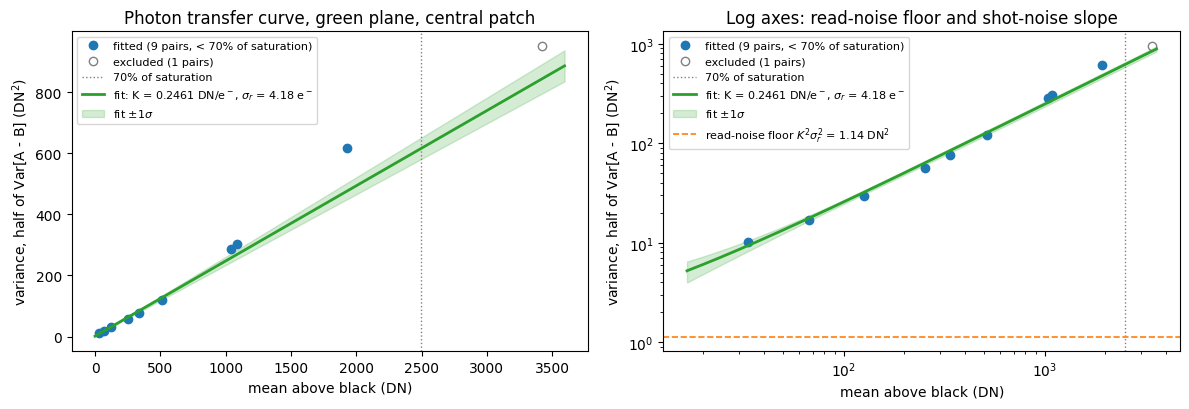

In [19]:
try:
    ptc_fit = fit_ptc(ptc_df.mean_DN, ptc_df.variance_DN2, full_scale=FULL_SCALE, frac=0.70)
except ValueError as err:
    ptc_fit = None
    print(f"! Fit not possible: {err}")

used = ((ptc_df.mean_DN > 0) & (ptc_df.mean_DN < 0.70 * FULL_SCALE)).to_numpy()
x, y = ptc_df.mean_DN.to_numpy(), ptc_df.variance_DN2.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, log in zip(axes, (False, True)):
    ax.plot(x[used], y[used], "o", ms=6, color="tab:blue",
            label=f"fitted ({used.sum()} pairs, < 70% of saturation)")
    ax.plot(x[~used], y[~used], "o", ms=6, mfc="none", color="gray",
            label=f"excluded ({(~used).sum()} pairs)")
    ax.axvline(0.70 * FULL_SCALE, ls=":", color="gray", lw=1, label="70% of saturation")

    if ptc_fit is not None:
        K, c, cov = ptc_fit["K"], ptc_fit["intercept"], ptc_fit["cov"]
        lo = max(x[x > 0].min() * 0.5, 1e-3) if log else 0
        xs = np.geomspace(lo, x.max() * 1.05, 200) if log else np.linspace(0, x.max() * 1.05, 200)
        line = K * xs + c
        X = np.c_[xs, np.ones_like(xs)]
        band = np.sqrt(np.einsum("ij,jk,ik->i", X, cov, X))   # 1-sigma on the fitted line
        ax.plot(xs, line, "-", lw=2, color="tab:green",
                label=f"fit: K = {K:.4f} DN/e$^-$, $\\sigma_r$ = {ptc_fit['read']:.2f} e$^-$")
        ax.fill_between(xs, line - band, line + band, color="tab:green", alpha=0.2,
                        label="fit $\\pm 1\\sigma$")
        if log and c > 0:
            ax.axhline(c, ls="--", lw=1.2, color="tab:orange",
                       label=f"read-noise floor $K^2\\sigma_r^2$ = {c:.2f} DN$^2$")

    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title("Log axes: read-noise floor and shot-noise slope")
    else:
        ax.set_title("Photon transfer curve, green plane, central patch")
    ax.set_xlabel("mean above black (DN)")
    ax.set_ylabel("variance, half of Var[A - B] (DN$^2$)")
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig("hw3_item6_ptc.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
if ptc_fit is not None:
    K, sK = ptc_fit["K"], ptc_fit["sig_K"]
    R, sR = ptc_fit["read"], ptc_fit["sig_read"]
    c, sc = ptc_fit["intercept"], ptc_fit["sig_intercept"]
    print(f"Fit through {ptc_fit['used'].sum()} pairs below 70% of saturation "
          f"(weighted by 1/variance)")
    print(f"  slope     K       = {K:.4f} ± {sK:.4f} DN/e-   ({100 * sK / K:.1f}%)")
    print(f"  intercept         = {c:.3f} ± {sc:.3f} DN²   "
          f"(K²σr² = {ptc_fit['read_var_DN2']:.3f} DN² after removing 1/12 DN² of rounding)")
    print(f"  read noise σr     = {R:.2f} ± {sR:.2f} e-      ({100 * sR / R:.1f}%)"
          if np.isfinite(R) else "  read noise: intercept is not positive, so σr is undefined")
    print(f"  inverse gain 1/K  = {1 / K:.3f} e-/DN")

Fit through 9 pairs below 70% of saturation (weighted by 1/variance)
  slope     K       = 0.2461 ± 0.0144 DN/e-   (5.8%)
  intercept         = 1.143 ± 1.382 DN²   (K²σr² = 1.059 DN² after removing 1/12 DN² of rounding)
  read noise σr     = 4.18 ± 2.89 e-      (69.1%)
  inverse gain 1/K  = 4.063 e-/DN


In [21]:
# Two checks on the fit before using it.
#
# 1. Read noise straight from the dark frames. The intercept is the weakest number in the fit:
#    the darkest pair sits at 33 DN, where shot noise (about 8 DN²) already dwarfs a 1-3 DN²
#    intercept. Half the variance of the difference of two dark frames measures the same
#    quantity directly (the fixed pattern cancels), plus the same 1/12 DN² of rounding.
dark_pairs = []
for t, grp in dark_ch[dark_ch.channel == "G1"].groupby("exposure_s"):
    files = sorted(grp.file)
    for fa, fb in zip(files[0::2], files[1::2]):        # consecutive frames, none used twice
        a, _, _ = green_plane(DARK_DIR / fa)
        b, _, _ = green_plane(DARK_DIR / fb)
        dark_pairs.append({"exposure": fmt_exposure(Fraction(t).limit_denominator(1_000_000)),
                           "frames": f"{fa}, {fb}",
                           "half_var_diff_DN2": np.var(a - b, ddof=1) / 2})
dark_rn = pd.DataFrame(dark_pairs)

K, sK = ptc_fit["K"], ptc_fit["sig_K"]
var_dark = dark_rn.half_var_diff_DN2.mean()
sig_var_dark = dark_rn.half_var_diff_DN2.std(ddof=1) / np.sqrt(len(dark_rn))
read_dark_DN = np.sqrt(var_dark - Q_VAR)
sig_read_dark_DN = 0.5 * sig_var_dark / read_dark_DN
read_dark_e = read_dark_DN / K
sig_read_dark_e = read_dark_e * np.hypot(sK / K, sig_read_dark_DN / read_dark_DN)

print(f"Dark frames, {len(dark_rn)} pairs of whole green planes "
      f"({dark_rn.half_var_diff_DN2.min():.3f} to {dark_rn.half_var_diff_DN2.max():.3f} DN²):")
print(f"  read-noise variance  {var_dark:.3f} - 1/12 = {read_dark_DN**2:.3f} DN²   "
      f"(fit intercept, same quantity: {ptc_fit['read_var_DN2']:.2f} ± {ptc_fit['sig_intercept']:.2f} DN²)")
print(f"  read noise           {read_dark_DN:.3f} ± {sig_read_dark_DN:.3f} DN  =  "
      f"{read_dark_e:.2f} ± {sig_read_dark_e:.2f} e-   (fit: {ptc_fit['read']:.2f} ± {ptc_fit['sig_read']:.2f} e-)")
print(f"  difference from the fit intercept: "
      f"{(read_dark_DN**2 - ptc_fit['read_var_DN2']) / ptc_fit['sig_intercept']:+.1f} sigma of the intercept")

# 2. How much the gain depends on the upper limit of the fit. On a sensor that follows the
#    model exactly the slope would not change; here variance/mean rises with signal.
rng_rows = []
for frac in (0.15, 0.30, 0.70):
    f = fit_ptc(ptc_df.mean_DN, ptc_df.variance_DN2, FULL_SCALE, frac=frac)
    rng_rows.append({"fit range": f"below {frac:.0%} of saturation", "pairs": int(f["used"].sum()),
                     "K (DN/e-)": f["K"], "sigma K": f["sig_K"]})
ptc_df["var_over_mean"] = ptc_df.variance_DN2 / ptc_df.mean_DN
print("\nVariance / mean by pair (equals K wherever shot noise dominates):")
print(ptc_df[["pair", "pct_saturation", "var_over_mean"]].round(3).to_string(index=False))
pd.DataFrame(rng_rows).style.format(precision=4).hide(axis="index")


Dark frames, 11 pairs of whole green planes (2.884 to 2.986 DN²):
  read-noise variance  2.952 - 1/12 = 2.868 DN²   (fit intercept, same quantity: 1.06 ± 1.38 DN²)
  read noise           1.694 ± 0.002 DN  =  6.88 ± 0.40 e-   (fit: 4.18 ± 2.89 e-)
  difference from the fit intercept: +1.3 sigma of the intercept

Variance / mean by pair (equals K wherever shot noise dominates):
 pair  pct_saturation  var_over_mean
    1           0.932          0.306
    2           1.877          0.253
    3           3.536          0.236
    4           7.110          0.223
    5           9.522          0.226
    6          14.394          0.234
    7          29.084          0.276
    8          30.481          0.280
    9          54.173          0.319
   10          95.969          0.278


fit range,pairs,K (DN/e-),sigma K
below 15% of saturation,6,0.2180,0.0044
below 30% of saturation,7,0.2289,0.0108
below 70% of saturation,9,0.2461,0.0144


Fitting the 9 pairs below 70% of saturation (pair 10, at 96%, is excluded), weighted by 1/variance:

- **Conversion gain:** K = 0.246 ± 0.014 DN/e⁻ (1/K = 4.06 e⁻/DN)
- **Read noise:** σr = 4.2 ± 2.9 e⁻, after removing the 1/12 DN² of rounding from the intercept

The read noise is barely constrained by the fit. The intercept (1.06 ± 1.38 DN²) is an extrapolation from a darkest pair whose shot-noise variance is already 8 DN².

The dark frames measure the same quantity directly: 2.87 DN², or σr = 1.694 DN = 6.9 ± 0.4 e⁻. That is within 1.3σ of the fit, and I use it for the dynamic range in item 8.

The gain also depends on how far up the fit reaches: 0.218 below 15% of saturation, 0.229 below 30%, and 0.246 below 70%. That is because variance/mean rises from 0.22 at 7–15% of saturation to 0.32 at 54%, where a sensor that followed the model would give a constant. The pair difference cancels fixed pattern, so the rise is not PRNU. It points to a response that is not quite linear, or to processing in the phone's raw pipeline. Either way, the gain carries a systematic uncertainty of roughly ±0.015 DN/e⁻ on top of the fit's ±0.014.

### Problem 7: Repeat the fit using the variance of a single frame at each level in place of the difference of pairs, and report both gains. The two disagree because one quantity present in the photographs is absent from the model. Name that quantity, and say which way it moves the gain and why.
_Deliverable: Both gains, their percentage difference, and a written explanation (2 to 3 sentences)._

In [22]:
single_var = []
for row in ptc_df.itertuples():
    fa, fb = row.frames.split(", ")
    a, black, _ = green_plane(WHITE_DIR / fa)
    b, _, _ = green_plane(WHITE_DIR / fb)
    # Variance of one frame on its own; averaging the two frames' single-frame
    # variances reduces scatter but keeps the fixed pattern in.
    single_var.append(0.5 * (np.var(center_patch(a), ddof=1) + np.var(center_patch(b), ddof=1)))

ptc_df["variance_single_DN2"] = single_var
ptc_df[["pair", "sheets", "exposure", "mean_DN", "variance_DN2", "variance_single_DN2"]].round(3)

,pair,sheets,exposure,mean_DN,variance_DN2,variance_single_DN2
0,1,10,1/30 s,33.237,10.165,10.214
1,2,10,1/15 s,66.936,16.906,17.399
2,3,10,1/8 s,126.140,29.741,30.882
3,4,10,1/4 s,253.596,56.674,61.225
4,5,10,1/3 s,339.660,76.779,85.241
5,6,10,1/2 s,513.429,120.260,141.029
6,7,10,1 s,1037.431,286.225,358.771
7,8,4,1/30 s,1087.245,304.414,352.666
8,9,3,1/30 s,1932.358,616.619,753.142
9,10,2,1/30 s,3423.208,951.279,1321.981


difference of pairs: K = 0.2461 ± 0.0144 DN/e-
single frame:        K = 0.2814 ± 0.0214 DN/e-
percentage difference (single vs. pair): +14.3%
excess variance fits (p * mean)^2 with p = 0.61% (fixed-pattern gain variation, PRNU)


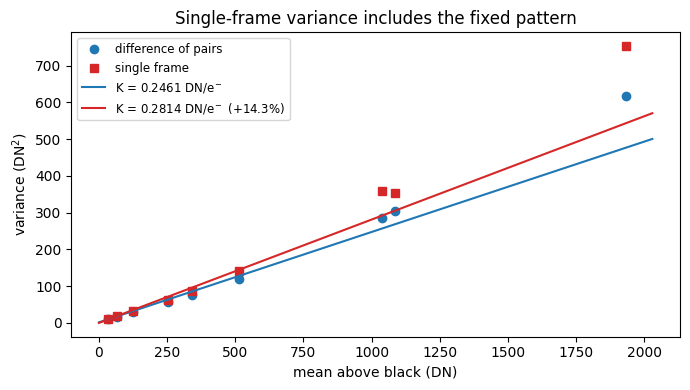

In [23]:
def compare_fits(mean, var_pair, var_single, full_scale, label=""):
    fp = fit_ptc(mean, var_pair, full_scale)
    fs = fit_ptc(mean, var_single, full_scale)
    pct_diff = 100 * (fs["K"] - fp["K"]) / fp["K"]

    # The excess single-frame variance should grow as (PRNU * mean)^2 if it is
    # fixed-pattern gain variation: fit excess = p^2 * mean^2 + const.
    u = fp["used"]
    m = np.asarray(mean)[u]
    excess = np.asarray(var_single)[u] - np.asarray(var_pair)[u]
    coef, *_ = np.linalg.lstsq(np.c_[m**2, np.ones_like(m)], excess, rcond=None)
    prnu = np.sqrt(coef[0]) if coef[0] > 0 else np.nan

    print(f"{label}difference of pairs: K = {fp['K']:.4f} ± {fp['sig_K']:.4f} DN/e-")
    print(f"{label}single frame:        K = {fs['K']:.4f} ± {fs['sig_K']:.4f} DN/e-")
    print(f"{label}percentage difference (single vs. pair): {pct_diff:+.1f}%")
    print(f"{label}excess variance fits (p * mean)^2 with p = {100 * prnu:.2f}% "
          f"(fixed-pattern gain variation, PRNU)")
    return fp, fs, pct_diff, prnu


try:
    fit_pair, fit_single, pct_diff, prnu_est = compare_fits(
        ptc_df.mean_DN, ptc_df.variance_DN2, ptc_df.variance_single_DN2, FULL_SCALE)
except ValueError as err:
    fit_pair = fit_single = None
    print(f"! Fit not possible: {err}")

if fit_single is not None:
    x = ptc_df.mean_DN.to_numpy()
    u = fit_pair["used"]
    xs = np.linspace(0, x[u].max() * 1.05, 100)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(x[u], ptc_df.variance_DN2[u], "o", color="tab:blue", label="difference of pairs")
    ax.plot(x[u], ptc_df.variance_single_DN2[u], "s", color="tab:red", label="single frame")
    ax.plot(xs, fit_pair["K"] * xs + fit_pair["intercept"], "-", color="tab:blue",
            label=f"K = {fit_pair['K']:.4f} DN/e$^-$")
    ax.plot(xs, fit_single["K"] * xs + fit_single["intercept"], "-", color="tab:red",
            label=f"K = {fit_single['K']:.4f} DN/e$^-$ ({pct_diff:+.1f}%)")
    ax.set_xlabel("mean above black (DN)"); ax.set_ylabel("variance (DN$^2$)")
    ax.set_title("Single-frame variance includes the fixed pattern")
    ax.legend(fontsize=8.5)
    fig.tight_layout(); fig.savefig("hw3_item7_single_vs_pair.png", dpi=150); plt.show()

In [24]:
sim_single = [0.5 * (np.var(a, ddof=1) + np.var(b, ddof=1)) for a, b in sim_pairs]
_ = compare_fits(sim_stats[:, 0], sim_stats[:, 1], sim_single,
                 psu.WHITE_LEVEL - psu.BLACK_LEVEL, label="[simulator] ")
print(f"[simulator] true PRNU = {100 * SIM_PRNU:.2f}%")

[simulator] difference of pairs: K = 0.4233 ± 0.0011 DN/e-
[simulator] single frame:        K = 0.4833 ± 0.0177 DN/e-
[simulator] percentage difference (single vs. pair): +14.2%
[simulator] excess variance fits (p * mean)^2 with p = 1.18% (fixed-pattern gain variation, PRNU)
[simulator] true PRNU = 1.20%


**Difference of pairs:** K = 0.2461 ± 0.0144 DN/e⁻. **Single frame:** K = 0.2814 ± 0.0214 DN/e⁻, which is 14.3% higher.

The missing quantity is fixed-pattern noise, mainly photo-response non-uniformity (PRNU). Each pixel's sensitivity differs slightly, so one frame's variance contains a pixel-to-pixel spread that adds (p·μ)², while the same pattern appears in both frames of a pair and cancels in their difference. Because that term grows with the square of the signal, the single-frame points bend upward and the fitted slope comes out steeper, so the single-frame fit overestimates the gain (here p ≈ 0.6%; on the simulator the same method recovers its 1.20% PRNU as 1.18%).

### Problem 8: Report your full well capacity in electrons and your dynamic range in stops. More than one convention exists for the low end of the dynamic range, and the number you get depends on which you adopt, so state yours.
_Deliverable: Full well in electrons, dynamic range in stops, and the criterion you used._

In [25]:
K, sK = ptc_fit["K"], ptc_fit["sig_K"]
R_fit, sR_fit = ptc_fit["read"], ptc_fit["sig_read"]

# --- Full well: the signal at which the raw values clip, in electrons --------
# This is the ADC-limited capacity (white minus black level, over the gain), which is
# what bounds the usable range of the raw data.
full_well = FULL_SCALE / K
sig_full_well = full_well * sK / K

# Cross-check: the variance turnover (EMVA 1288 "saturation capacity").
i_peak = int(np.argmax(ptc_df.variance_DN2))
peak_mean = ptc_df.mean_DN.iloc[i_peak]
peak_bracketed = 0 < i_peak < len(ptc_df) - 1

# --- Read noise for the low end ----------------------------------------------
# Adopted: the dark-frame value from the item 6 cross-check. It is measured directly,
# its uncertainty is a fraction of a percent, and in DN it does not depend on K at all,
# so FW / sigma_r = FULL_SCALE / sigma_r(DN). The fit intercept is shown for comparison.
R = read_dark_e
R_DN, sR_DN = read_dark_DN, sig_read_dark_DN


def stops(ratio):
    return np.log2(ratio)


# 1. Read-noise floor (adopted): lowest usable signal = sigma_r, i.e. SNR = 1 from read noise alone.
dr_read = stops(FULL_SCALE / R_DN)
sig_dr_read = (sR_DN / R_DN) / np.log(2)
dr_read_fit = stops(full_well / R_fit) if np.isfinite(R_fit) else np.nan

# 2. EMVA 1288: signal where SNR = 1 counting its own shot noise,
#    mu / sqrt(mu + sigma_r^2) = 1  ->  mu_min = (1 + sqrt(1 + 4 sigma_r^2)) / 2
mu_min_emva = (1 + np.sqrt(1 + 4 * R**2)) / 2
dr_emva = stops(full_well / mu_min_emva)

# 3. A stricter photographic floor: signal where SNR = 10.
#    mu^2 = 100 (mu + sigma_r^2)  ->  mu = (100 + sqrt(100^2 + 400 sigma_r^2)) / 2
mu_min_snr10 = (100 + np.sqrt(100**2 + 400 * R**2)) / 2
dr_snr10 = stops(full_well / mu_min_snr10)

print(f"Full well (clip level)   {full_well:,.0f} ± {sig_full_well:,.0f} e-   "
      f"= ({FULL_SCALE:.0f} DN white minus black) / K")
if peak_bracketed:
    print(f"Variance turnover        {peak_mean / K:,.0f} e-   "
          f"(pair {ptc_df.pair.iloc[i_peak]}, cross-check)")
else:
    print(f"Variance turnover        not bracketed: the largest variance is at the "
          f"{'highest' if i_peak else 'lowest'} level, so no pair sits past the clipping knee")

dr_table = pd.DataFrame({
    "low-end criterion": ["read-noise floor: signal = sigma_r, dark frames (adopted)",
                          "read-noise floor: signal = sigma_r, PTC fit intercept",
                          "EMVA 1288: SNR = 1 including shot noise",
                          "photographic: SNR = 10"],
    "lowest signal (e-)": [R, R_fit, mu_min_emva, mu_min_snr10],
    "dynamic range (stops)": [dr_read, dr_read_fit, dr_emva, dr_snr10],
})
print(f"\nDynamic range (adopted, read-noise floor): {dr_read:.2f} stops "
      f"(statistical uncertainty {sig_dr_read:.3f} stops) "
      f"= log2({FULL_SCALE:.0f} DN / {R_DN:.3f} DN)")
dr_table.style.format(precision=2).hide(axis="index")


Full well (clip level)   14,492 ± 846 e-   = (3567 DN white minus black) / K
Variance turnover        not bracketed: the largest variance is at the highest level, so no pair sits past the clipping knee

Dynamic range (adopted, read-noise floor): 11.04 stops (statistical uncertainty 0.002 stops) = log2(3567 DN / 1.694 DN)


low-end criterion,lowest signal (e-),dynamic range (stops)
"read-noise floor: signal = sigma_r, dark frames (adopted)",6.88,11.04
"read-noise floor: signal = sigma_r, PTC fit intercept",4.18,11.76
EMVA 1288: SNR = 1 including shot noise,7.40,10.94
photographic: SNR = 10,135.06,6.75


**Full well:** 14,500 ± 850 e⁻. This is the clip level: white minus black (3567 DN) divided by K. It is the largest signal the raw file can record, set by the 12-bit range rather than by the photodiode itself.

**Dynamic range:** 11.0 stops. The criterion is full well divided by read noise: the low end is the signal equal to the read noise, i.e. SNR = 1 from read noise alone. With the dark-frame read noise this is 3567 DN / 1.694 DN, so the gain cancels and the ratio rests on two directly measured numbers. The statistical uncertainty is only 0.002 stops; the real limit is how well the model describes this sensor.

The other conventions give 10.9 stops (EMVA 1288, SNR = 1 including the signal's own shot noise) and 6.7 stops (SNR = 10). The fit's read noise would give 11.8 stops, but with a large uncertainty.

The variance-turnover cross-check is not available here. The brightest pair (96%) still has the largest variance, so no pair lies past the clipping knee, although its variance/mean has already fallen from 0.32 to 0.28.

## Part 3: Signal to Noise
### Problem 9: Plot your measured signal-to-noise ratio against signal in electrons on logarithmic axes, draw the curve predicted by your fitted gain and read noise over it, and mark the knee.
_Deliverable: The figure, the knee in electrons, and one sentence on whether your captures actually reach into both regimes._

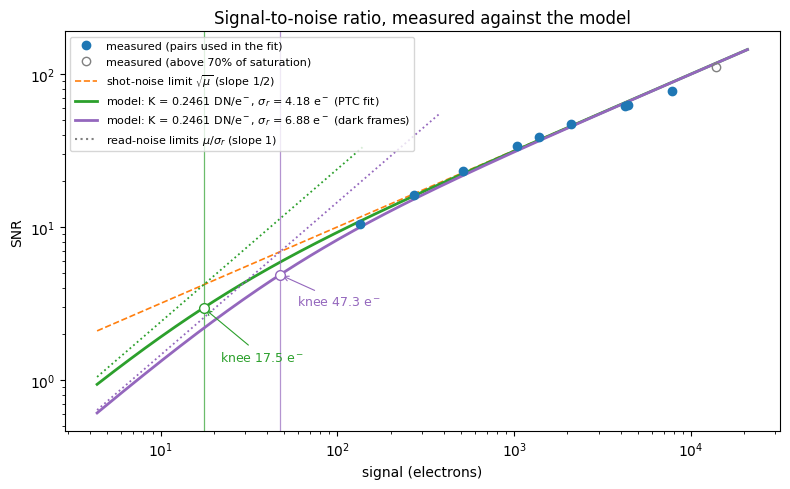

Knee, PTC-fit read noise:    mu = sigma_r^2 = 17.5 e-  (4.3 DN above black)
Knee, dark-frame read noise: mu = sigma_r^2 = 47.3 e-  (11.7 DN above black)
Signal range measured: 135 to 13,908 e-; darkest pair is 2.9x the higher knee
Pairs below the knee (read-noise regime): 0 of 10
Darkest pair: SNR 10.42 measured, 11.62 for pure shot noise, 10.93 / 10.00 for the fit / dark-frame model
Median |measured - model| / model, PTC-fit read noise: 5.0% over the fitted pairs
Median |measured - model| / model, dark-frame read noise: 6.1% over the fitted pairs


In [26]:
K = ptc_fit["K"]
R_fit = ptc_fit["read"]          # read noise from the PTC fit: the model this item asks for
R_dark = read_dark_e             # read noise from the dark frames (item 6 cross-check, used in item 8)
knee_fit, knee_dark = R_fit**2, R_dark**2     # the knee: shot variance mu equals read variance sigma_r^2


def snr_model(mu, read):
    return mu / np.sqrt(mu + read**2)


snr_df = ptc_df[["pair", "sheets", "exposure", "mean_DN", "variance_DN2"]].copy()
snr_df = snr_df[(snr_df.mean_DN > 0) & (snr_df.variance_DN2 > 0)]
snr_df["signal_e"] = snr_df.mean_DN / K
snr_df["snr_measured"] = snr_df.mean_DN / np.sqrt(snr_df.variance_DN2)
snr_df["snr_model_fit"] = snr_model(snr_df.signal_e, R_fit)
snr_df["snr_model_dark"] = snr_model(snr_df.signal_e, R_dark)
snr_df["in_fit"] = snr_df.mean_DN < 0.70 * FULL_SCALE

mu = np.geomspace(min(knee_fit, knee_dark) / 4, snr_df.signal_e.max() * 1.5, 300)

fig, ax = plt.subplots(figsize=(8, 5))
fit_pts, out_pts = snr_df[snr_df.in_fit], snr_df[~snr_df.in_fit]
ax.loglog(fit_pts.signal_e, fit_pts.snr_measured, "o", ms=6, color="tab:blue", zorder=4,
          label="measured (pairs used in the fit)")
if len(out_pts):
    ax.loglog(out_pts.signal_e, out_pts.snr_measured, "o", ms=6, mfc="none", color="gray", zorder=4,
              label="measured (above 70% of saturation)")
ax.loglog(mu, np.sqrt(mu), "--", lw=1.2, color="tab:orange",
          label=r"shot-noise limit $\sqrt{\mu}$ (slope 1/2)")
for read, knee, color, name, dy in ((R_fit, knee_fit, "tab:green", "PTC fit", -38),
                                    (R_dark, knee_dark, "tab:purple", "dark frames", -22)):
    ax.loglog(mu, snr_model(mu, read), "-", lw=2, color=color,
              label=f"model: K = {K:.4f} DN/e$^-$, $\\sigma_r$ = {read:.2f} e$^-$ ({name})")
    near = mu[mu < 8 * knee]
    ax.loglog(near, near / read, ":", lw=1.3, color=color)          # read-noise limit, slope 1
    ax.axvline(knee, color=color, lw=0.9, alpha=0.7)
    ax.plot(knee, np.sqrt(knee / 2), "o", ms=7, mfc="white", color=color, zorder=5)  # SNR = sqrt(mu/2)
    ax.annotate(f"knee {knee:.1f} e$^-$", xy=(knee, np.sqrt(knee / 2)), xytext=(12, dy),
                textcoords="offset points", fontsize=9, color=color,
                arrowprops=dict(arrowstyle="->", lw=0.8, color=color))
ax.plot([], [], ":", color="gray", label=r"read-noise limits $\mu/\sigma_r$ (slope 1)")
ax.set_xlabel("signal (electrons)")
ax.set_ylabel("SNR")
ax.set_title("Signal-to-noise ratio, measured against the model")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("hw3_item9_snr.png", dpi=150, bbox_inches="tight")
plt.show()

darkest = snr_df.iloc[snr_df.signal_e.argmin()]
print(f"Knee, PTC-fit read noise:    mu = sigma_r^2 = {knee_fit:.1f} e-  ({knee_fit * K:.1f} DN above black)")
print(f"Knee, dark-frame read noise: mu = sigma_r^2 = {knee_dark:.1f} e-  ({knee_dark * K:.1f} DN above black)")
print(f"Signal range measured: {snr_df.signal_e.min():.0f} to {snr_df.signal_e.max():,.0f} e-; "
      f"darkest pair is {darkest.signal_e / knee_dark:.1f}x the higher knee")
print(f"Pairs below the knee (read-noise regime): {(snr_df.signal_e < max(knee_fit, knee_dark)).sum()} "
      f"of {len(snr_df)}")
print(f"Darkest pair: SNR {darkest.snr_measured:.2f} measured, {np.sqrt(darkest.signal_e):.2f} for pure "
      f"shot noise, {darkest.snr_model_fit:.2f} / {darkest.snr_model_dark:.2f} for the fit / dark-frame model")
for col, name in (("snr_model_fit", "PTC-fit"), ("snr_model_dark", "dark-frame")):
    err = (snr_df.snr_measured - snr_df[col]) / snr_df[col]
    print(f"Median |measured - model| / model, {name} read noise: "
          f"{100 * np.median(np.abs(err[snr_df.in_fit])):.1f}% over the fitted pairs")


The figure plots measured SNR (each pair's mean divided by the square root of its variance) against signal in electrons. Over it is the model SNR = μ / √(μ + σr²), using the fitted gain.

**Knee:** μ = σr² = **17.5 e⁻** (4.3 DN above black) with the fitted read noise, as the item asks. With the better-measured dark-frame read noise, the knee is at **47 e⁻** (11.7 DN).

**Both regimes?** No: my captures reach only the shot-noise regime. The darkest pair sits at 135 e⁻, 2.9× above even the higher knee. The read-noise regime shows only as the start of the bend: the darkest pair's SNR is 10.4, against 11.6 for pure shot noise, falling between the two model curves (10.9 and 10.0). Reaching below the knee would take a pair about 3× dimmer than the darkest, roughly two more sheets of paper at 1/30 s.

Elsewhere the measurements follow the model within a median of 5%. The 54% pair falls below it, because variance/mean rises at high signal (item 6).

### Problem 10: Check whether your DNG carries a NoiseProfile tag, which is the manufacturer's own noise model. If it is present, convert it into a gain and a read noise that can be compared against yours; the tag is written in units of normalized signal, so the conversion is a matter of carrying the white level minus the black level through the model.
_Deliverable: The vendor figures beside your own, or a statement that the tag is absent._

In [27]:
NOISE_PROFILE_TAG = 51041          # DNG NoiseProfile: (S, O) per color plane

def read_noise_profile(path):
    """The NoiseProfile tag as an (n_planes, 2) array of (S, O), or None if absent.
    Checks IFD0 and its SubIFDs, since the raw image usually sits in a SubIFD."""
    with tifffile.TiffFile(path) as t:
        first = t.pages[0]
        pages = [first] + (list(first.pages) if first.pages else [])
        for p in pages:
            tag = p.tags.get(NOISE_PROFILE_TAG)
            if tag is not None:
                return np.asarray(tag.value, dtype=float).ravel().reshape(-1, 2)
    return None


profiles = {f.name: read_noise_profile(f) for f in dng_files(WHITE_DIR)}
present = {k: v for k, v in profiles.items() if v is not None}
print(f"NoiseProfile present in {len(present)} of {len(profiles)} flat-field files")

if present:
    distinct = {tuple(v.ravel()) for v in present.values()}
    if len(distinct) > 1:
        print(f"! {len(distinct)} different profiles across files:")
        for k, v in present.items():
            print(f"    {k}: {v.ravel()}")
    profile = next(iter(present.values()))
    print(f"Profile (S, O) per plane, normalized units:\n{profile}")

NoiseProfile present in 20 of 20 flat-field files
Profile (S, O) per plane, normalized units:
[[8.85807e-05 9.87416e-07]]


In [28]:
if present:
    K, sK = ptc_fit["K"], ptc_fit["sig_K"]

    # Normalized signal x = (D - B) / (W - B), so Var(x) = S x + O becomes
    #   Var(D) = (W - B) S (D - B) + (W - B)^2 O
    # Matching K (D - B) + K^2 sigma_r^2 term by term:
    #   K_vendor = S (W - B),   sigma_r,vendor = sqrt(O) (W - B) DN = sqrt(O) / S electrons
    plane = 1 if len(profile) == 3 else 0      # green plane if given per color, else the only one
    S, O = profile[plane]
    K_vendor = S * FULL_SCALE
    R_vendor_DN = np.sqrt(O) * FULL_SCALE      # read noise in DN: needs no gain at all
    R_vendor = R_vendor_DN / K_vendor          # = sqrt(O) / S, in electrons

    fit_read_DN = np.sqrt(ptc_fit["read_var_DN2"])
    sig_fit_read_DN = ptc_fit["sig_intercept"] / (2 * fit_read_DN)
    vendor_df = pd.DataFrame({
        "quantity": ["conversion gain K (DN/e-)", "read noise (e-)", "read noise (DN)"],
        "vendor (NoiseProfile)": [K_vendor, R_vendor, R_vendor_DN],
        "mine: PTC fit": [K, ptc_fit["read"], fit_read_DN],
        "± (fit)": [sK, ptc_fit["sig_read"], sig_fit_read_DN],
        "mine: dark frames": [np.nan, read_dark_e, read_dark_DN],
    })
    vendor_df["fit vs. vendor (%)"] = 100 * (vendor_df["mine: PTC fit"] / vendor_df["vendor (NoiseProfile)"] - 1)
    vendor_df["dark vs. vendor (%)"] = 100 * (vendor_df["mine: dark frames"] / vendor_df["vendor (NoiseProfile)"] - 1)
    print(f"Using plane {plane} of {len(profile)}: S = {S:.4e}, O = {O:.4e}; "
          f"white - black = {FULL_SCALE:.0f} DN")
    display(vendor_df.style.format(precision=3, na_rep="–").hide(axis="index"))

    # Where does the vendor model agree with the measurement? Predict each pair's variance from it.
    vcmp = ptc_df[["pair", "pct_saturation", "mean_DN", "variance_DN2"]].copy()
    vcmp["vendor_variance_DN2"] = K_vendor * vcmp.mean_DN + R_vendor_DN**2
    vcmp["measured / vendor"] = vcmp.variance_DN2 / vcmp.vendor_variance_DN2
    print("\nVariance of each pair, measured against the NoiseProfile prediction:")
    display(vcmp.style.format({"pct_saturation": "{:.1f}", "mean_DN": "{:.1f}", "variance_DN2": "{:.1f}",
                               "vendor_variance_DN2": "{:.1f}", "measured / vendor": "{:.2f}"})
                .hide(axis="index"))
else:
    print("The NoiseProfile tag (51041) is absent from these DNGs, so there are no vendor "
          "figures to compare against.")


Using plane 0 of 1: S = 8.8581e-05, O = 9.8742e-07; white - black = 3567 DN


quantity,vendor (NoiseProfile),mine: PTC fit,± (fit),mine: dark frames,fit vs. vendor (%),dark vs. vendor (%)
conversion gain K (DN/e-),0.316,0.246,0.014,–,-22.101,–
read noise (e-),11.218,4.182,2.888,6.881,-62.722,-38.663
read noise (DN),3.544,1.029,0.672,1.694,-70.961,-52.219



Variance of each pair, measured against the NoiseProfile prediction:


pair,pct_saturation,mean_DN,variance_DN2,vendor_variance_DN2,measured / vendor
1,0.9,33.2,10.2,23.1,0.44
2,1.9,66.9,16.9,33.7,0.50
3,3.5,126.1,29.7,52.4,0.57
4,7.1,253.6,56.7,92.7,0.61
5,9.5,339.7,76.8,119.9,0.64
6,14.4,513.4,120.3,174.8,0.69
7,29.1,1037.4,286.2,340.4,0.84
8,30.5,1087.2,304.4,356.1,0.85
9,54.2,1932.4,616.6,623.1,0.99
10,96.0,3423.2,951.3,1094.2,0.87


The NoiseProfile tag is present in all 20 flat-field DNGs, with a single plane: S = 8.858 × 10⁻⁵ and O = 9.874 × 10⁻⁷ in normalized units. Carried through white minus black (3567 DN):

- **Vendor gain:** S × 3567 = **0.316 DN/e⁻**. Mine is 0.246 ± 0.014 DN/e⁻, 22% lower.
- **Vendor read noise:** √O × 3567 = **3.54 DN**, or √O / S = **11.2 e⁻**. Mine is 1.69 DN (6.9 e⁻) from the dark frames, 52% lower in DN. The fit gives 1.03 ± 0.67 DN.

The comparison in DN is the cleaner one, because it doesn't depend on either gain. Measured directly in the dark frames, the noise is half what the profile says.

Predicting each pair's variance from the profile shows where the two disagree. The profile matches my measured variance at 54% of saturation (ratio 0.99) but overstates it more and more toward black, by a factor of 2.3 at the darkest pair. Its line is both steeper and higher at zero than mine. The file doesn't say how Apple derived the profile, but it behaves like a conservative model (for example one fitted at high signal, or one meant to set a raw converter's noise reduction) rather than a measurement of this sensor at ISO 50.

## Part 4: Dark Current
### Problem 11: Fit the dark current from the capped frames you took in item 3 by plotting their mean against exposure time and converting the slope to electrons per second with your gain. Dark current roughly doubles for every 6 to 8 degrees Celsius, so note whether the phone was warm. If your longest available exposure is only a fraction of a second, the result may be indistinguishable from zero, and in that case an upper bound with an argument behind it is the correct answer.
_Deliverable: The figure, and the dark current in electrons per second with an uncertainty, or a defended upper bound._

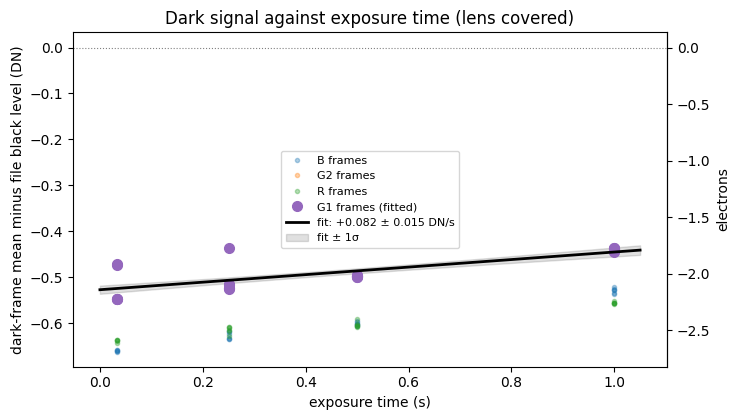

channel  slope_DN_per_s  sigma_DN_per_s  intercept_DN  significance  e_per_s  spread_at_fixed_t_DN
      B          0.1337          0.0035       -0.6637       38.3678   0.5431                0.0173
     G1          0.0821          0.0152       -0.5270        5.3992   0.3334                0.0909
     G2          0.0770          0.0152       -0.5263        5.0636   0.3129                0.0923
      R          0.0824          0.0036       -0.6394       22.6403   0.3349                0.0197

G1: slope +0.0821 ± 0.0152 DN/s over 0 to 1 s, 23 frames; K = 0.2461 DN/e-  ->  0.33 ± 0.06 e-/s if all of it were dark current
Channels disagree: slopes 0.077 to 0.134 DN/s; level spread between frames at one exposure time up to 0.092 DN (G1: 0.091 DN, vs. 0.082 DN of trend over the full 1 s)
95% upper bound (steepest channel, B): dark current < 0.60 e-/s
  -> at the longest exposure (1 s) that is < 0.60 e- of dark signal; its shot noise adds < 0.60 e-² to a read-noise variance of 47 e-² (1.3%)


In [29]:
DARK_CHANNEL = "G1"        # same Bayer site as green_plane(), so the gain K applies directly

def fit_dark(df):
    t = df.exposure_s.to_numpy()
    y = (df.mean_DN - df.black_DN).to_numpy()
    (slope, icpt), cov = np.polyfit(t, y, 1, cov=True)    # cov scaled by the actual scatter
    return slope, icpt, cov

K, sK = ptc_fit["K"], ptc_fit["sig_K"]
rows = []
for ch, grp in dark_ch.groupby("channel", sort=False):
    slope, icpt, cov = fit_dark(grp)
    s_slope = np.sqrt(cov[0, 0])
    rows.append({"channel": ch, "slope_DN_per_s": slope, "sigma_DN_per_s": s_slope,
                 "intercept_DN": icpt, "significance": slope / s_slope})
dark_fits = pd.DataFrame(rows)

g = dark_ch[dark_ch.channel == DARK_CHANNEL]
slope, icpt, cov = fit_dark(g)
s_slope = np.sqrt(cov[0, 0])
dc = slope / K                                                   # e-/s
s_dc = abs(dc) * np.sqrt((s_slope / slope) ** 2 + (sK / K) ** 2) if slope else s_slope / K
t_max = g.exposure_s.max()

# --- figure ------------------------------------------------------------------
ts = np.linspace(0, t_max * 1.05, 100)
X = np.c_[ts, np.ones_like(ts)]
band = np.sqrt(np.einsum("ij,jk,ik->i", X, cov, X))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
for ch, grp in dark_ch.groupby("channel", sort=False):
    if ch != DARK_CHANNEL:
        ax.plot(grp.exposure_s, grp.mean_DN - grp.black_DN, ".", alpha=0.35, label=f"{ch} frames")
ax.plot(g.exposure_s, g.mean_DN - g.black_DN, "o", ms=7, color="tab:purple",
        label=f"{DARK_CHANNEL} frames (fitted)")
ax.plot(ts, slope * ts + icpt, "-", lw=2, color="k",
        label=f"fit: {slope:+.3f} ± {s_slope:.3f} DN/s")
ax.fill_between(ts, slope * ts + icpt - band, slope * ts + icpt + band,
                color="k", alpha=0.12, label="fit ± 1σ")
ax.axhline(0, color="gray", lw=0.8, ls=":")
ax.set_xlabel("exposure time (s)")
ax.set_ylabel("dark-frame mean minus file black level (DN)")
sec = ax.secondary_yaxis("right", functions=(lambda d: d / K, lambda e: e * K))
sec.set_ylabel("electrons")
ax.set_title("Dark signal against exposure time (lens covered)")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
fig.savefig("hw3_item11_dark_current.png", dpi=150, bbox_inches="tight")
plt.show()

# --- result ------------------------------------------------------------------
# Same conversion gain for every channel: it is set by the readout, not the color filter.
dark_fits["e_per_s"] = dark_fits.slope_DN_per_s / K
# Largest spread (max - min) of the dark level between frames at the SAME exposure time.
spread_fixed = (dark_ch.groupby(["channel", "exposure_s"]).mean_DN.agg(lambda s: s.max() - s.min())
                .groupby("channel").max())
dark_fits["spread_at_fixed_t_DN"] = dark_fits.channel.map(spread_fixed)
print(dark_fits.round(4).to_string(index=False))
print(f"\n{DARK_CHANNEL}: slope {slope:+.4f} ± {s_slope:.4f} DN/s over 0 to {t_max:g} s, "
      f"{len(g)} frames; K = {K:.4f} DN/e-  ->  {dc:.2f} ± {s_dc:.2f} e-/s if all of it were dark current")

# Why this is reported as an upper bound rather than a measurement:
#  - the four channels disagree by more than their errors, and dark current does not depend on
#    the color filter over a pixel;
#  - the dark level jumps between frames at the same exposure time by as much as the whole trend;
#  - the frames were shot in order of exposure time within about a minute, so a slow drift of
#    the black offset is indistinguishable from dark current.
# So the steepest channel's slope, plus 1.645 sigma (one-sided 95%), with the gain's uncertainty
# included, bounds the dark current from above.
worst = dark_fits.loc[dark_fits.slope_DN_per_s.idxmax()]
dc_worst = worst.slope_DN_per_s / K
rel = np.hypot(worst.sigma_DN_per_s / worst.slope_DN_per_s, sK / K)
ub = dc_worst * (1 + 1.645 * rel)
print(f"Channels disagree: slopes {dark_fits.slope_DN_per_s.min():.3f} to "
      f"{dark_fits.slope_DN_per_s.max():.3f} DN/s; level spread between frames at one exposure time "
      f"up to {dark_fits.spread_at_fixed_t_DN.max():.3f} DN (G1: {spread_fixed[DARK_CHANNEL]:.3f} DN, "
      f"vs. {slope * t_max:.3f} DN of trend over the full {t_max:g} s)")
print(f"95% upper bound (steepest channel, {worst.channel}): dark current < {ub:.2f} e-/s")
print(f"  -> at the longest exposure ({t_max:g} s) that is < {ub * t_max:.2f} e- of dark signal; its shot "
      f"noise adds < {ub * t_max:.2f} e-² to a read-noise variance of {read_dark_e**2:.0f} e-² "
      f"({100 * ub * t_max / read_dark_e**2:.1f}%)")

The fit through the green (G1) channel gives a slope of +0.082 ± 0.015 DN/s. Taken at face value, that is 0.33 ± 0.06 e⁻/s.

I do not trust that as a measurement of dark current, for three reasons:

- **The channels disagree.** The four Bayer channels rise at 0.077 to 0.134 DN/s, which is more than their errors allow. Dark current does not depend on the color filter over a pixel.
- **The level jumps at a fixed exposure.** The dark level shifts between frames at the same exposure time by up to 0.09 DN in green, more than the whole trend (0.08 DN over 1 s).
- **Exposure order matches time order.** I shot the frames in order of exposure time, within about a minute, so a slow drift of the black offset would look exactly like dark current.

I therefore report an upper bound. Taking the steepest channel (blue), adding 1.645σ and including the gain's uncertainty gives **dark current < 0.6 e⁻/s** (one-sided 95%). That is consistent with the app's longest exposure being only 1 s. At 1 s it amounts to less than 0.6 e⁻, whose shot noise adds about 1.3% to the 47 e⁻² read-noise variance, so dark current is negligible at every exposure this app allows.

**Phone temperature:** *[TODO: say whether the phone felt cool or warm when you took the dark frames, e.g. "The phone was at room temperature (cool to the touch) and had not been in use beforehand." Dark current roughly doubles every 6–8 °C, so a warm phone would raise the bound.]*

## Part 5: Linear Light
### Problem 12: Construct a checkerboard of pure black and pure white pixels, exactly half of each, and compute its mean twice: once by averaging the sRGB-encoded values directly, and once by linearizing, averaging, and re-encoding.
_Deliverable: Both values, and one sentence identifying which of them is the brightness a camera pointed at that checkerboard would have recorded._

In [30]:
def srgb_decode(v):
    """Piecewise sRGB transfer function, encoded [0, 1] -> linear [0, 1]."""
    v = np.clip(v, 0, 1)
    return np.where(v <= 0.04045, v / 12.92, ((v + 0.055) / 1.055) ** 2.4)

# Round-trip check that the two curves are inverses
_t = np.linspace(0, 1, 1001)
assert np.allclose(srgb_decode(srgb_encode(_t)), _t, atol=1e-12)

# Checkerboard of pure black and pure white, exactly half of each (sRGB-encoded values)
N = 256
yy, xx = np.indices((N, N))
board = ((xx + yy) % 2).astype(float)          # 0 = black, 1 = white
assert board.mean() == 0.5 and board.size % 2 == 0

mean_encoded = board.mean()                                   # average the encoded values
mean_linear = srgb_encode(srgb_decode(board).mean())          # linearize, average, re-encode

# For comparison: the same calculation with a bare 2.2 power law instead of the sRGB curve
mean_gamma22 = srgb_decode(board).mean() ** (1 / 2.2)

try:                                                          # optional cross-check
    import colour
    check = colour.cctf_encoding(colour.cctf_decoding(board, "sRGB").mean(), "sRGB")
    print(f"colour-science cross-check of the linear-light mean: {check:.4f}")
except ImportError:
    pass

checker_df = pd.DataFrame({
    "method": ["average the sRGB-encoded values",
               "linearize, average, re-encode (sRGB curve)",
               "linearize, average, re-encode (bare 2.2 power, for comparison)"],
    "encoded value [0, 1]": [mean_encoded, mean_linear, mean_gamma22],
    "8-bit level": [255 * mean_encoded, 255 * mean_linear, 255 * mean_gamma22],
    "linear light it stands for": [srgb_decode(mean_encoded), srgb_decode(mean_linear),
                                   srgb_decode(mean_gamma22)],
})
checker_df.style.format({"encoded value [0, 1]": "{:.4f}", "8-bit level": "{:.1f}",
                         "linear light it stands for": "{:.4f}"}).hide(axis="index")

method,"encoded value [0, 1]",8-bit level,linear light it stands for
average the sRGB-encoded values,0.5000,127.5,0.2140
"linearize, average, re-encode (sRGB curve)",0.7354,187.5,0.5000
"linearize, average, re-encode (bare 2.2 power, for comparison)",0.7297,186.1,0.4915


**Averaging the encoded values:** 0.500, which is 127.5 on an 8-bit scale.

**Linearizing, averaging and re-encoding:** 0.735, which is 187.5. (A bare 2.2 power law gives 186.1, close but not exact.)

The second value is the brightness a camera pointed at that checkerboard would record. A camera's sensor counts photons, so it averages linear light: half the pixels emit full light and half emit none, giving 50% of white. That re-encodes to 0.735. The encoded average of 0.500 stands for only 21% of white in linear light.

### Problem 13: Do the same thing to real data. Take one of your checkerboard calibration captures from Exercise 1, extract a green plane, encode it to sRGB, and then reduce it by a factor of eight two ways: by averaging the encoded values, and by averaging in linear light and encoding afterward.
_Deliverable: The two reduced images and their difference, the mean absolute difference in 8-bit levels, and one sentence on where in the image the error concentrates._

In [31]:
CHECKER_PATH = CAPTURE_ROOT / "IMG_0322.DNG"
REDUCE = 8

def linear_green(path):
    """Green plane as linear light in [0, 1] of the raw range.
    Handles both a Bayer DNG (one green site of the mosaic) and a demosaiced
    LinearRaw DNG such as Apple ProRAW (the G channel of the RGB stack)."""
    with rawpy.imread(str(path)) as r:
        is_bayer = r.raw_pattern is not None
        if not is_bayer:                                # LinearRaw: already RGB, already linearized
            desc = r.color_desc.decode()
            gi = desc.index("G")
            g = r.raw_image_visible[..., gi].astype(np.float64)   # copy before the file closes
            black = float(r.black_level_per_channel[gi])
            white = float(r.white_level)
            kind = f"LinearRaw (demosaiced) {r.raw_image_visible.shape[:2]}, channel {gi}"
    if is_bayer:
        g, black, white = green_plane(path)
        kind = "Bayer mosaic, one green site"
    return np.clip((g - black) / (white - black), 0, 1), kind, black, white


def block_mean(x, factor=REDUCE):
    h, w = (s // factor * factor for s in x.shape)
    return x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))


lin, kind, blk, wht = linear_green(CHECKER_PATH)
enc = srgb_encode(lin)                                  # full-resolution sRGB-encoded green plane

reduced_encoded = block_mean(enc)                       # 1. average the encoded values
reduced_linear = srgb_encode(block_mean(lin))           # 2. average in linear light, then encode
diff_8bit = 255 * (reduced_linear - reduced_encoded)    # positive where linear averaging is brighter

mad = np.mean(np.abs(diff_8bit))
print(f"{CHECKER_PATH.name}: {kind}; black {blk:.0f}, white {wht:.0f}")
print(f"Full resolution {lin.shape}, reduced by {REDUCE} to {reduced_linear.shape}")
print(f"Mean absolute difference: {mad:.2f} 8-bit levels (max {np.abs(diff_8bit).max():.1f})")

IMG_0322.DNG: LinearRaw (demosaiced) (3024, 4032), channel 1; black 0, white 65535
Full resolution (3024, 4032), reduced by 8 to (378, 504)
Mean absolute difference: 0.20 8-bit levels (max 16.8)


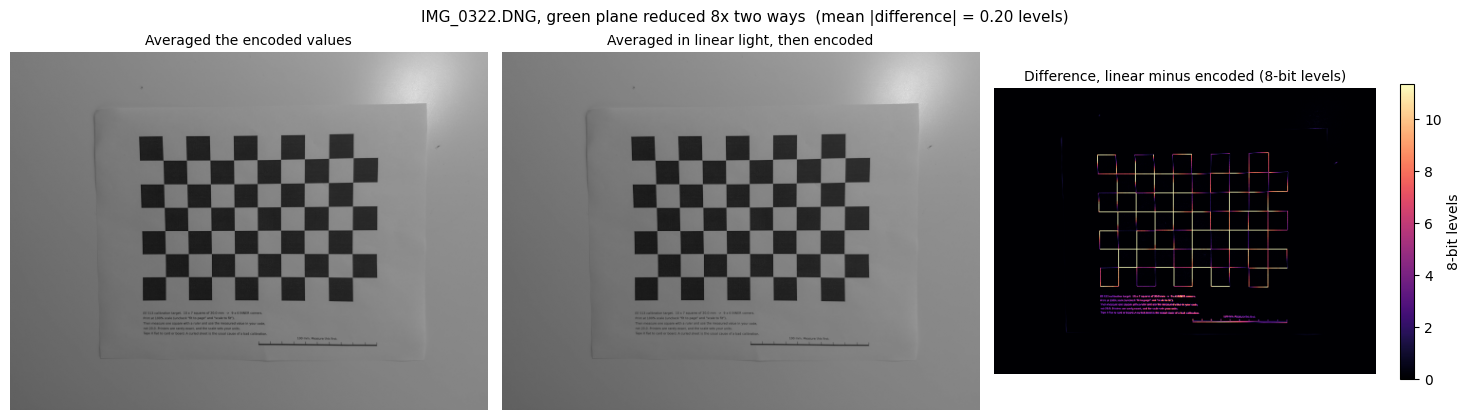

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, img, title in ((axes[0], reduced_encoded, "Averaged the encoded values"),
                       (axes[1], reduced_linear, "Averaged in linear light, then encoded")):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10); ax.axis("off")
im = axes[2].imshow(diff_8bit, cmap="magma", vmin=0, vmax=np.percentile(diff_8bit, 99.5))
axes[2].set_title("Difference, linear minus encoded (8-bit levels)", fontsize=10); axes[2].axis("off")
fig.colorbar(im, ax=axes[2], shrink=0.8, label="8-bit levels")
fig.suptitle(f"{CHECKER_PATH.name}, green plane reduced {REDUCE}x two ways  "
             f"(mean |difference| = {mad:.2f} levels)", fontsize=11)
fig.tight_layout()
fig.savefig("hw3_item13_reduction.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# Sort the reduced blocks by how much the light varies inside them.
local_var = block_mean(lin**2) - block_mean(lin)**2          # within-block variance, linear
local_sd = np.sqrt(np.clip(local_var, 0, None))
edges = local_sd >= np.percentile(local_sd, 90)
flat = local_sd <= np.percentile(local_sd, 50)
print(f"Blocks with the most variation inside them (top 10%): mean |diff| = "
      f"{np.abs(diff_8bit[edges]).mean():.2f} levels")
print(f"Uniform blocks (bottom 50%):                          mean |diff| = "
      f"{np.abs(diff_8bit[flat]).mean():.2f} levels")
print(f"Share of the total absolute error in the top 10% of blocks: "
      f"{100 * np.abs(diff_8bit[edges]).sum() / np.abs(diff_8bit).sum():.0f}%")
print(f"Fraction of blocks where linear averaging is brighter: {100 * (diff_8bit > 0).mean():.1f}%")

Blocks with the most variation inside them (top 10%): mean |diff| = 1.89 levels
Uniform blocks (bottom 50%):                          mean |diff| = 0.01 levels
Share of the total absolute error in the top 10% of blocks: 95%
Fraction of blocks where linear averaging is brighter: 100.0%


The two reductions differ by a mean of 0.20 8-bit levels (up to 16.8), and the error concentrates almost entirely on the edges of the squares and the printed text: blocks that straddle a black-white boundary average 1.9 levels darker when the encoded values are averaged, which carries 95% of the total error, while uniform regions of paper or square interiors differ by only 0.01 levels.

IMG_0322 is an Apple ProRAW capture: a demosaiced, linear DNG with black level 0 and white level 65535, rather than a Bayer mosaic. So the "green plane" here is the G channel of its RGB data at full resolution, normalized to the file's black and white levels.

## Part 6: Reflections
### Problem 14: What did you learn from this assignment?
_Deliverable: A brief written response._

*Topics covered in this homework (pick the ones you want to write about, then delete this list):*

- Photon counting follows Poisson statistics, so shot-noise variance equals the mean signal in electrons
- The sensor noise model Var[D] = K(E[D] − B) + K²σr², and the photon transfer curve built from it
- Measuring variance from the difference of two frames, so the fixed pattern cancels
- Conversion gain, read noise and full well: numbers phone makers don't publish, measured from photographs
- Testing analysis code on a simulated sensor with known answers before trusting it on real data (which exposed the 1/12 DN² rounding term)
- Fixed-pattern noise (PRNU), and why single-frame variance overestimates the gain
- Weighted least-squares fitting, and propagating fit uncertainties into derived quantities
- Why the PTC intercept is a weak way to get read noise, and dark-frame differences as a direct check
- Dynamic range depends on the low-end convention (read-noise floor, EMVA 1288, SNR = 10)
- The two SNR regimes (shot-noise and read-noise limited) and the knee at μ = σr²
- Comparing my measurements with the manufacturer's DNG NoiseProfile tag
- Black level, dark frames, and why dark current can't be measured with exposures of 1 s or less
- Real sensors departing from the textbook model: the curved PTC, and spatially correlated noise in iPhone "raw" files
- Capture practice: avoiding saturation, fixing ISO, checking metadata, screen flicker, building a flat field from paper and an overcast window, sky drift between frames
- Reading DNG metadata: EXIF, black and white levels, CFA pattern, Bayer versus LinearRaw (ProRAW)
- Linear light versus sRGB encoding: averaging encoded values gives the wrong brightness, and the error concentrates at edges

### Problem 15: What questions, if any, do you have for me after completing this assignment?
_Deliverable: A brief written response._